# Test matrices generated by the PEG algorithm

In [1]:
from coder.Coder import Coder
from decoder.Decoder import Decoder
from matrix_generators.PEG import PEG
from matrix_generators.PEG_fast import PEG_fast
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from DE.DE import density_evolution_p

In [30]:
PEG(100, 150, 4).peg()

In [31]:
PEG(300, 450, 4).peg()

In [32]:
PEG(600, 900, 4).peg()

In [33]:
PEG(1000, 1500, 4).peg()

In [34]:
PEG(500, 750, 4).peg()

KeyboardInterrupt: 

In [8]:
H = np.loadtxt('data/H_matrix/H5_1000x1500.txt', delimiter=',', dtype=np.int8)
print(np.mean(H.sum(axis=1)))
np.unique(H.sum(axis=1))

7.5


array([7, 8])

In [20]:
np.mean(H.sum(axis=0))
np.unique(H.sum(axis=0))

array([6])

In [21]:
np.unique(np.sum(H, axis=1), return_counts=True)

(array([ 8,  9, 10]), array([10, 80, 10]))

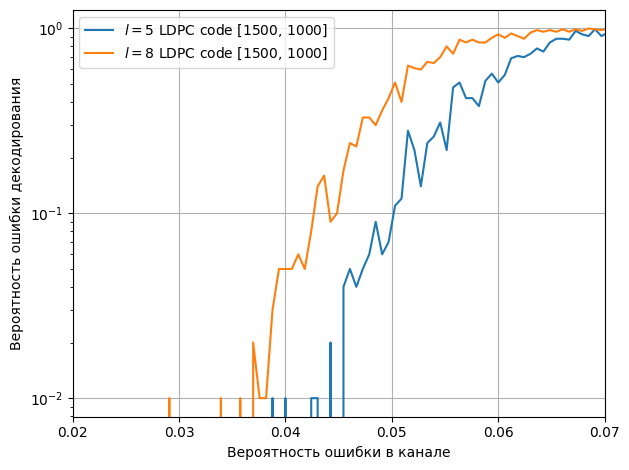

In [10]:
from coder.Coder import Coder
from decoder.Decoder import Decoder
from matrix_generators.PEG import PEG
from matrix_generators.PEG_fast import PEG_fast
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from DE.DE import density_evolution_p

deep = 100
repeat = 100
p = np.linspace(0.02, 0.08, 100)

ber11 = Decoder.bitflipping_decoding_for_many(
    np.loadtxt('data/H_matrix/H5_1000x1500.txt', delimiter=',', dtype=np.int8), 
    np.zeros(1500, dtype=np.int16), 
    p=p, 
    repeat=repeat,
    deep=deep, 
    ber=False, 
    with_threshold=False
)
ber22 = Decoder.bitflipping_decoding_for_many(
    np.loadtxt('data/H_matrix/H8_1000x1500.txt', delimiter=',', dtype=np.int8), 
    np.zeros(1500, dtype=np.int16), 
    p=p, 
    repeat=repeat,
    deep=deep, 
    ber=False, 
    with_threshold=False
)
plt.plot(p, ber11, label=f'$l = 5$ LDPC code [1500, 1000]')
plt.plot(p, ber22, label=f'$l = 8$ LDPC code [1500, 1000]')
plt.legend()
plt.ylabel('Вероятность ошибки декодирования')
plt.xlabel('Вероятность ошибки в канале')
plt.yscale('log')
plt.grid()
plt.xlim(0.02, 0.07)
plt.tight_layout()
plt.savefig('data/H.pdf')
plt.show()